In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from torch.utils.data import TensorDataset, DataLoader, random_split

In [3]:
df_r=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\3DatasetsCombined.csv")
df_p=pd.read_csv(r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\combined_processed_v1.csv")

In [4]:
# RAW dataset
df_r = df_r.dropna(subset=['text'])
df_r['text'] = df_r['text'].astype(str)
df_r = df_r.reset_index(drop=True)

texts_r = df_r['text']
labels_r = df_r['class'].values

In [5]:
# CLEAN dataset
df_p = df_p.dropna(subset=['clean_text'])
df_p['clean_text'] = df_p['clean_text'].astype(str)
df_p = df_p.reset_index(drop=True)

texts_p = df_p['clean_text']
labels_p = df_p['class'].values

In [6]:
tokenizer_r = Tokenizer(num_words=10000)
tokenizer_r.fit_on_texts(texts_r)

X_r = pad_sequences(tokenizer_r.texts_to_sequences(texts_r), maxlen=100)
y_r = labels_r

In [7]:
tokenizer_p = Tokenizer(num_words=10000)
tokenizer_p.fit_on_texts(texts_p)

X_p = pad_sequences(tokenizer_p.texts_to_sequences(texts_p), maxlen=100)
y_p = labels_p

In [8]:
Xr_train, Xr_test, yr_train, yr_test, idxr_train, idxr_test = train_test_split(
    X_r, y_r, df_r.index,
    test_size=0.2,
    random_state=42,
    stratify=y_r
)

In [9]:
Xp_train, Xp_test, yp_train, yp_test, idxp_train, idxp_test = train_test_split(
    X_p, y_p, df_p.index,
    test_size=0.2,
    random_state=42,
    stratify=y_p
)

In [10]:
from sklearn.utils.class_weight import compute_class_weight

classes_p = np.unique(yp_train)
weights_p = compute_class_weight(
    class_weight='balanced',
    classes=classes_p,
    y=yp_train
)

class_weights_p = torch.tensor(weights_p, dtype=torch.float)

In [11]:
Xr_train = torch.tensor(Xr_train, dtype=torch.long)
Xr_test  = torch.tensor(Xr_test, dtype=torch.long)

yr_train = torch.tensor(yr_train, dtype=torch.long)
yr_test  = torch.tensor(yr_test, dtype=torch.long)

In [12]:
Xp_train = torch.tensor(Xp_train, dtype=torch.long)
Xp_test  = torch.tensor(Xp_test, dtype=torch.long)

yp_train = torch.tensor(yp_train, dtype=torch.long)
yp_test  = torch.tensor(yp_test, dtype=torch.long)

In [13]:
#cnn model architecture
class TextCNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        num_classes=2,
        kernel_sizes=(3, 4, 5),
        num_filters=64,
        dropout=0.3
    ):
        super(TextCNN, self).__init__()

        # Embedding
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # 🔥 Deep multi-kernel conv blocks
        self.conv_blocks = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(embed_dim, num_filters, k, padding=1),
                nn.ReLU(),

                nn.Conv1d(num_filters, num_filters, k, padding=1),
                nn.ReLU(),

                nn.Conv1d(num_filters, num_filters, k, padding=1),
                nn.ReLU()
            )
            for k in kernel_sizes
        ])

        # Dropout
        self.dropout = nn.Dropout(dropout)

        # Fully connected (deeper)
        self.fc1 = nn.Linear(len(kernel_sizes) * num_filters, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, num_classes)

    def forward(self, x):

        # Embedding
        x = self.embedding(x)            # (batch, seq, embed)
        x = x.permute(0, 2, 1)           # (batch, embed, seq)

        conv_results = []

        for block in self.conv_blocks:
            c = block(x)                               # deep conv
            c = F.max_pool1d(c, kernel_size=c.shape[2])
            conv_results.append(c.squeeze(2))

        x = torch.cat(conv_results, dim=1)

        x = self.dropout(x)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        logits = self.fc3(x)

        return logits

In [14]:
model_r = TextCNN(vocab_size=10000)

criterion_r = nn.CrossEntropyLoss()  # NO weights
optimizer_r = torch.optim.Adam(model_r.parameters(), lr=0.001)

In [15]:
model_p = TextCNN(vocab_size=10000)

criterion_p = nn.CrossEntropyLoss(weight=class_weights_p)
optimizer_p = torch.optim.Adam(model_p.parameters(), lr=0.001)

In [16]:
epochs = 5

for epoch in range(epochs):
    model_r.train()

    outputs = model_r(Xr_train)
    loss = criterion_r(outputs, yr_train)

    optimizer_r.zero_grad()
    loss.backward()
    optimizer_r.step()

    preds = torch.argmax(outputs, dim=1)
    acc = (preds == yr_train).float().mean()

    print(f"[RAW] Epoch {epoch+1} - Loss: {loss.item():.4f} - Acc: {acc.item():.4f}")

[RAW] Epoch 1 - Loss: 0.7025 - Acc: 0.4221
[RAW] Epoch 2 - Loss: 0.6940 - Acc: 0.4844
[RAW] Epoch 3 - Loss: 0.6873 - Acc: 0.5734
[RAW] Epoch 4 - Loss: 0.6807 - Acc: 0.5803
[RAW] Epoch 5 - Loss: 0.6753 - Acc: 0.5788


In [17]:
for epoch in range(epochs):
    model_p.train()

    outputs = model_p(Xp_train)
    loss = criterion_p(outputs, yp_train)

    optimizer_p.zero_grad()
    loss.backward()
    optimizer_p.step()

    preds = torch.argmax(outputs, dim=1)
    acc = (preds == yp_train).float().mean()

    print(f"[CLEAN] Epoch {epoch+1} - Loss: {loss.item():.4f} - Acc: {acc.item():.4f}")

[CLEAN] Epoch 1 - Loss: 0.6932 - Acc: 0.4949
[CLEAN] Epoch 2 - Loss: 0.6921 - Acc: 0.5262
[CLEAN] Epoch 3 - Loss: 0.6902 - Acc: 0.5629
[CLEAN] Epoch 4 - Loss: 0.6865 - Acc: 0.6079
[CLEAN] Epoch 5 - Loss: 0.6801 - Acc: 0.6449


In [18]:
model_r.eval()
with torch.no_grad():
    outputs = model_r(Xr_test)
    preds_r = torch.argmax(outputs, dim=1).numpy()

y_true_r = yr_test.numpy()

In [19]:
model_p.eval()
with torch.no_grad():
    outputs = model_p(Xp_test)
    preds_p = torch.argmax(outputs, dim=1).numpy()

y_true_p = yp_test.numpy()

In [20]:
print("=== CNN v2 RAW ===")
print("Accuracy:", accuracy_score(y_true_r, preds_r))
print("Precision:", precision_score(y_true_r, preds_r))
print("Recall:", recall_score(y_true_r, preds_r))
print("F1:", f1_score(y_true_r, preds_r))

=== CNN v2 RAW ===
Accuracy: 0.5777315296566077
Precision: 0.5777315296566077
Recall: 1.0
F1: 0.7323572088115025


In [21]:
print("\n=== CNN v2 CLEAN + WEIGHTS ===")
print("Accuracy:", accuracy_score(y_true_p, preds_p))
print("Precision:", precision_score(y_true_p, preds_p))
print("Recall:", recall_score(y_true_p, preds_p))
print("F1:", f1_score(y_true_p, preds_p))


=== CNN v2 CLEAN + WEIGHTS ===
Accuracy: 0.6969192339716903
Precision: 0.780970625798212
Recall: 0.660842939481268
F1: 0.7159024390243902


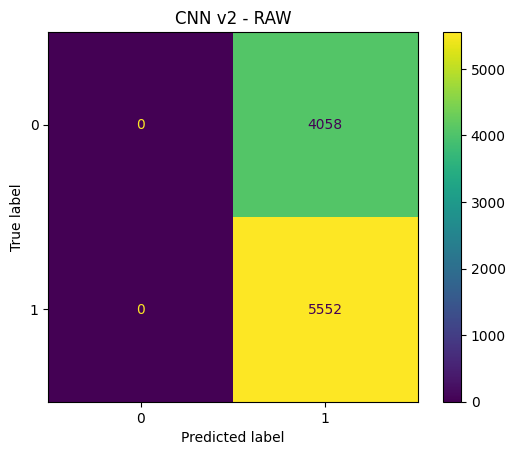

In [22]:
cm_r = confusion_matrix(y_true_r, preds_r)
ConfusionMatrixDisplay(cm_r).plot()
plt.title("CNN v2 - RAW")
plt.show()

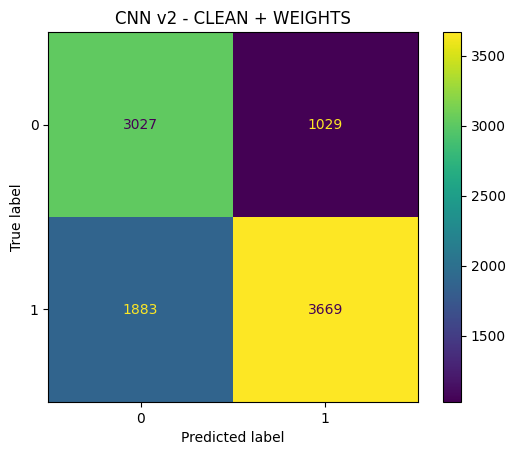

In [23]:
cm_p = confusion_matrix(y_true_p, preds_p)
ConfusionMatrixDisplay(cm_p).plot()
plt.title("CNN v2 - CLEAN + WEIGHTS")
plt.show()

In [24]:
wrong_r = np.where(preds_r != y_true_r)[0]
wrong_idx_r = idxr_test[wrong_r]

df_r.loc[wrong_idx_r][['text', 'class']].head(10)

,text,class
11128,"I think the, Apple uses BSD without compensati...",0
34507,Deconstructed lemon tart #mkr,0
6519,"is a good option, but it's a partial solution....",0
3790,@hayyllss Merry Christmas Hun ! &#127877;&#127...,0
8283,about halfway through.,0
45650,"""you are HOT!!!\xa0\xa0 Damn!""",0
11242,I realize that you are a big mouthed liar who ...,0
11688,"""it won't let me ""like"" your comment...""",0
511,Does it bother anyone else that the planet of ...,0
44833,&#8220;@AdderallHadMe: Adderall had me killing...,0


In [25]:
wrong_p = np.where(preds_p != y_true_p)[0]
wrong_idx_p = idxp_test[wrong_p]

df_p.loc[wrong_idx_p][['clean_text', 'class']].head(10)

,clean_text,class
31517,ive went through 50 fag in 5 day not very happ...,1
13446,rt fighting over a hoe is one of the lamest th...,1
43437,lookdumbfuck i am just pointing out the asshoi...,1
11115,my high school need to gon and throw a hood re...,1
40061,u coon cant wait to wear them oreo j,1
14858,another fricking instant restaurant round mkr,0
39434,rt my tbt i learn the english from that jabron...,1
24944,omg i didnt realize,0
3831,8220 no need to thank me killing nigger is it ...,1
430,choudary tell the truth about islam islam ha n...,1


In [26]:
#testing on real data samples
#Step 1: load datasets and get basic info
df_1=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\labeled_data.csv')
df_2=pd.read_csv(r'C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\train_E6oV3lV.csv')

In [28]:
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

lemmatizer = WordNetLemmatizer()

def full_preprocess(text):
    text = str(text).lower()
    
    # Step 2: remove URLs, mentions, keep hashtag words
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    
    # Step 3: normalize elongated words
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Step 4: remove punctuation + extra spaces
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    
    # Step 5: lemmatization
    tokens = word_tokenize(text)
    text = " ".join([lemmatizer.lemmatize(word) for word in tokens])
    
    return text

In [30]:
df_1 = df_1.rename(columns={'tweet': 'text'})
df_1['label'] = df_1['class'].apply(lambda x: 0 if x == 2 else 1)

# preprocessed
df_1['clean_text'] = df_1['text'].apply(full_preprocess)

In [31]:
df_2 = df_2.rename(columns={'tweet': 'text'})

# preprocessed
df_2['clean_text'] = df_2['text'].apply(full_preprocess)

In [35]:
# --- MODEL R inputs ---
X1_raw_r   = pad_sequences(tokenizer_r.texts_to_sequences(df_1['text']), maxlen=100)
X1_clean_r = pad_sequences(tokenizer_r.texts_to_sequences(df_1['clean_text']), maxlen=100)

# --- MODEL P inputs ---
X1_raw_p   = pad_sequences(tokenizer_p.texts_to_sequences(df_1['text']), maxlen=100)
X1_clean_p = pad_sequences(tokenizer_p.texts_to_sequences(df_1['clean_text']), maxlen=100)

In [36]:
# --- MODEL R inputs ---
X2_raw_r   = pad_sequences(tokenizer_r.texts_to_sequences(df_2['text']), maxlen=100)
X2_clean_r = pad_sequences(tokenizer_r.texts_to_sequences(df_2['clean_text']), maxlen=100)

# --- MODEL P inputs ---
X2_raw_p   = pad_sequences(tokenizer_p.texts_to_sequences(df_2['text']), maxlen=100)
X2_clean_p = pad_sequences(tokenizer_p.texts_to_sequences(df_2['clean_text']), maxlen=100)

In [37]:
X1_raw_r   = torch.tensor(X1_raw_r, dtype=torch.long)
X1_clean_r = torch.tensor(X1_clean_r, dtype=torch.long)
X1_raw_p   = torch.tensor(X1_raw_p, dtype=torch.long)
X1_clean_p = torch.tensor(X1_clean_p, dtype=torch.long)

X2_raw_r   = torch.tensor(X2_raw_r, dtype=torch.long)
X2_clean_r = torch.tensor(X2_clean_r, dtype=torch.long)
X2_raw_p   = torch.tensor(X2_raw_p, dtype=torch.long)
X2_clean_p = torch.tensor(X2_clean_p, dtype=torch.long)

In [38]:
def predict_cnnv2(model, X):
    model.eval()
    with torch.no_grad():
        outputs = model(X)
        preds = torch.argmax(outputs, dim=1)
    return preds.numpy()

In [39]:
def evaluate_preds(y_true, y_pred, title=""):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    print(f"\n=== {title} ===")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1 Score:  {f1:.4f}")

In [ ]:
y1 = df_1['label'].values
y2 = df_2['label'].values

In [40]:
print("=== DF1 RESULTS (CNN v2) ===")

# Model R
evaluate_preds(y1, predict_cnnv2(model_r, X1_raw_r),   "Model R on RAW")
evaluate_preds(y1, predict_cnnv2(model_r, X1_clean_r), "Model R on CLEAN")

# Model P
evaluate_preds(y1, predict_cnnv2(model_p, X1_raw_p),   "Model P on RAW")
evaluate_preds(y1, predict_cnnv2(model_p, X1_clean_p), "Model P on CLEAN")

=== DF1 RESULTS (CNN v2) ===

=== Model R on RAW ===
Accuracy:  0.8320
Precision: 0.8320
Recall:    1.0000
F1 Score:  0.9083

=== Model R on CLEAN ===
Accuracy:  0.8320
Precision: 0.8320
Recall:    1.0000
F1 Score:  0.9083

=== Model P on RAW ===
Accuracy:  0.7227
Precision: 0.9070
Recall:    0.7429
F1 Score:  0.8168

=== Model P on CLEAN ===
Accuracy:  0.7736
Precision: 0.9139
Recall:    0.8035
F1 Score:  0.8552


In [41]:
print("\n=== DF2 RESULTS (CNN v2) ===")

# Model R
evaluate_preds(y2, predict_cnnv2(model_r, X2_raw_r),   "Model R on RAW")
evaluate_preds(y2, predict_cnnv2(model_r, X2_clean_r), "Model R on CLEAN")

# Model P
evaluate_preds(y2, predict_cnnv2(model_p, X2_raw_p),   "Model P on RAW")
evaluate_preds(y2, predict_cnnv2(model_p, X2_clean_p), "Model P on CLEAN")


=== DF2 RESULTS (CNN v2) ===

=== Model R on RAW ===
Accuracy:  0.0701
Precision: 0.0701
Recall:    1.0000
F1 Score:  0.1311

=== Model R on CLEAN ===
Accuracy:  0.0701
Precision: 0.0701
Recall:    1.0000
F1 Score:  0.1311

=== Model P on RAW ===
Accuracy:  0.6092
Precision: 0.0683
Recall:    0.3617
F1 Score:  0.1149

=== Model P on CLEAN ===
Accuracy:  0.6508
Precision: 0.0664
Recall:    0.3046
F1 Score:  0.1090
